# Лабораторная работа №1. Алгоритм KNN

**Задачи:**
- **Классификация** - сентимент-анализ русскоязычных отзывов на аниме (3 класса: отрицательный / нейтральный / положительный).
- **Регрессия** - прогноз влияния новостной статьи на цены акций российских компаний (оценка `answer` от -95 до +95).

## 1. Выбор начальных условий

### 1.1 Набор данных для классификации - `russian-anime-reviews-dataset`
Собран самостоятельно (парсинг отзывов), ни с кем из группы не пересекается. Практическая задача - автоматическая
модерация и агрегация отзывов: определение тональности текста позволяет считать рейтинг произведения, находить
негативные отзывы для модерации, строить рекомендательные системы. Особенность - три класса, причём "нейтральный"
класс семантически пересекается с соседними, что делает задачу нетривиальной.

### 1.2 Набор данных для регрессии - `russian-financial-news-ranking`
Тоже собран самостоятельно. Каждой новости (Интерфакс, "Копейка рубль бережёт", The Экономист) сопоставлена оценка
ожидаемого влияния на котировки российских компаний. Практическая задача - ранжирование потока финансовых новостей
для трейдеров/аналитиков: какие новости стоит прочитать первыми и в какую сторону они двигают рынок.
Колонка `reasoning` (текстовое обоснование оценки) **исключается** - это прямая утечка целевой переменной.

### 1.3 Метрики качества
- **Классификация:** основная - **macro-F1** (классы несбалансированы: 41% / 35% / 24%, а ошибки на редком
  отрицательном классе важны не меньше), дополнительная - **accuracy** (интерпретируемость).
- **Регрессия:** основная - **MAE** (средняя ошибка в пунктах шкалы, устойчива к выбросам и понятна бизнесу),
  дополнительные - **RMSE** (сильнее штрафует грубые ошибки в знаке/масштабе) и **R2** (доля объяснённой дисперсии,
  сравнение с константным прогнозом).

### Общие функции
Загрузка и разбиение данных, очистка текста, LSA-признаки, метаданные новостей, метрики и сохранение результатов. Эта ячейка одинакова во всех ЛР, чтобы разбиение train/test и метрики совпадали.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent  # ноутбук запускается из labs/
DATA = ROOT / "data"
RESULTS = Path.cwd() / "results"
CACHE = DATA / "cache"
SEED = 42

# Имена признаков (заполняются при построении признаков) - для графиков важности
FEATURE_NAMES = {}
STAT_NAMES = ["log_len", "log_words", "excl_%", "quest_%", "smile_balance_%"]

CLASSES = ["Отрицательный", "Нейтральный", "Положительный"]


def clean_text(s: str) -> str:
    """Нижний регистр, удаление смайлов вида :lonely:, ссылок и лишних пробелов."""
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r":[a-z_]+:", " ", s)
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()


def load_anime():
    """Отзывы на аниме -> (тексты train, тексты test, y train, y test). y: 0/1/2 = отр/нейтр/пол."""
    df = pd.read_csv(DATA / "anime" / "Anime_reviews_RU.csv", index_col=0).dropna(subset=["Text"])
    y = df["Rate"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    X = df["Text"].map(clean_text).to_numpy()
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


def load_finnews():
    """Финансовые новости -> (df train, df test, y train, y test).

    Колонка reasoning исключается: это объяснение оценки, сгенерированное вместе с answer,
    т.е. прямая утечка целевой переменной.
    """
    df = pd.read_csv(DATA / "finnews" / "data.csv", index_col=0)
    df["text"] = df["article_text"].map(clean_text)
    y = df["answer"].to_numpy(dtype=float)
    X = df[["text", "sphere", "source", "date"]].reset_index(drop=True)
    return train_test_split(X, y, test_size=0.2, random_state=SEED)


def text_stats(texts) -> np.ndarray:
    """Простые числовые признаки текста: длина, число слов, доля '!', '?', заглавных скобок-смайлов."""
    rows = []
    for t in texts:
        n = max(len(t), 1)
        rows.append([np.log1p(len(t)), np.log1p(len(t.split())), t.count("!") / n * 100,
                     t.count("?") / n * 100, (t.count(")") - t.count("(")) / n * 100])
    return np.array(rows)


def svd_features(train_texts, test_texts, name, n_components=200):
    """TF-IDF (слова 1-2 граммы) -> TruncatedSVD (LSA) + статистики текста. Кэшируется на диск."""
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / f"{name}_n{len(train_texts)}_svd{n_components}.npz"
    if path.exists():
        d = np.load(path)
        FEATURE_NAMES[name] = list(d["names"])
        return d["tr"], d["te"]
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True)
    a, b = tfidf.fit_transform(train_texts), tfidf.transform(test_texts)
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    tr = np.hstack([svd.fit_transform(a), text_stats(train_texts)])
    te = np.hstack([svd.transform(b), text_stats(test_texts)])
    # Имя LSA-компоненты = 3 слова/биграммы с наибольшим весом в ней (для интерпретации важности)
    vocab = tfidf.get_feature_names_out()
    names = [f"svd{i}: " + "/".join(vocab[np.argsort(-c)[:3]]) for i, c in enumerate(svd.components_)] + STAT_NAMES
    np.savez(path, tr=tr, te=te, names=np.array(names))
    FEATURE_NAMES[name] = names
    return tr, te


def finnews_meta(train_df, test_df):
    """One-hot сферы и источника + день недели публикации."""
    enc = OneHotEncoder(handle_unknown="ignore")
    cols = ["sphere", "source"]
    a = enc.fit_transform(train_df[cols]).toarray()
    b = enc.transform(test_df[cols]).toarray()
    wd = lambda d: pd.get_dummies(pd.to_datetime(d["date"]).dt.weekday).reindex(columns=range(7), fill_value=0).to_numpy(float)
    FEATURE_NAMES["meta"] = list(enc.get_feature_names_out(cols)) + [f"weekday_{i}" for i in range(7)]
    return np.hstack([a, wd(train_df)]), np.hstack([b, wd(test_df)])


def plot_importance(values, names, title, top=20, ax=None):
    """Горизонтальная диаграмма top-N признаков по важности."""
    s = pd.Series(np.asarray(values), index=list(names)).sort_values(ascending=False)[:top][::-1]
    ax = ax or plt.subplots(figsize=(7, 0.3 * top + 1))[1]
    s.plot.barh(ax=ax, title=title, color="#4C72B0")
    return s[::-1]


def stack(*mats):
    """Склейка разреженных/плотных матриц по признакам в CSR."""
    return sparse.hstack([sparse.csr_matrix(m) for m in mats]).tocsr()


def clf_metrics(y_true, y_pred) -> dict:
    """Классификация: macro-F1 (основная, классы несбалансированы) и accuracy."""
    return {"f1_macro": round(float(f1_score(y_true, y_pred, average="macro")), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4)}


def reg_metrics(y_true, y_pred) -> dict:
    """Регрессия: MAE (основная, в пунктах шкалы), RMSE и R2."""
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
            "r2": round(float(r2_score(y_true, y_pred)), 4)}


def save_results(lab: str, results: dict):
    """Сохраняет метрики лабораторной в labs/results/<lab>.json для итогового ноутбука."""
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / f"{lab}.json").write_text(json.dumps(results, ensure_ascii=False, indent=2))


def results_table(results: dict) -> pd.DataFrame:
    """Словарь {задача: {этап: метрики}} -> таблица."""
    return pd.DataFrame([{"задача": t, "этап": s, **m} for t, d in results.items() for s, m in d.items()])

In [2]:
# Структура для метрик: задача -> этап -> {метрика: значение}
res = {"classification": {}, "regression": {}}

In [3]:
# KNN из sklearn и нормализация векторов (для косинусной близости)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import normalize

In [4]:
# Загружаем оба набора с фиксированным разбиением train/test (80/20, seed=42) - одинаковым во всех ЛР
Xa_tr, Xa_te, ya_tr, ya_te = load_anime()       # отзывы: тексты и классы 0/1/2
Xf_tr, Xf_te, yf_tr, yf_te = load_finnews()     # новости: таблица (text, sphere, source, date) и оценка влияния
print("anime:", len(Xa_tr), len(Xa_te), " finnews:", len(Xf_tr), len(Xf_te))

anime: 58572 14643  finnews: 8268 2067


### Разведочный анализ
Распределение классов, длины текстов и целевой переменной регрессии.

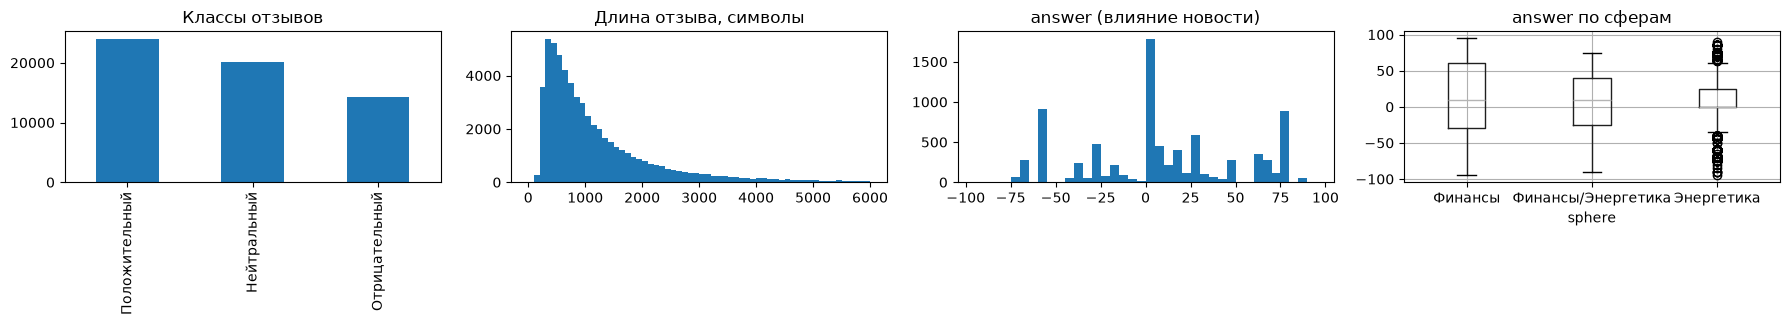

In [5]:
# Распределение классов (train), длин отзывов, целевой переменной и её разброса по сферам
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
pd.Series(ya_tr).map(dict(enumerate(CLASSES))).value_counts().plot.bar(ax=ax[0], title="Классы отзывов")
ax[1].hist([len(t) for t in Xa_tr], bins=60, range=(0, 6000)); ax[1].set_title("Длина отзыва, символы")
ax[2].hist(yf_tr, bins=38); ax[2].set_title("answer (влияние новости)")
pd.DataFrame({"answer": yf_tr, "sphere": Xf_tr["sphere"].values}).boxplot("answer", by="sphere", ax=ax[3])
ax[3].set_title("answer по сферам"); plt.suptitle(""); plt.tight_layout(); plt.show()

Видно: классы умеренно несбалансированы; тексты длинные с тяжёлым хвостом; целевая переменная регрессии
мультимодальна (пик в нуле - "нейтральные" новости, пики около +-60-75), сфера слабо влияет на распределение.

In [6]:
# Фолды кросс-валидации (только на train): стратифицированные для классификации
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
kf = KFold(3, shuffle=True, random_state=SEED)

## 2. Бейзлайн

Минимальный пайплайн: мешок слов TF-IDF (20 000 самых частых слов, параметры по умолчанию) + KNN из sklearn
с параметрами по умолчанию (k=5, равные веса, евклидова метрика). TF-IDF-векторы L2-нормированы, поэтому
евклидово расстояние здесь монотонно связано с косинусным.

In [7]:
# Бейзлайн-признаки: TF-IDF по словам, обучается только на train
vec_a = TfidfVectorizer(max_features=20000)
A_tr, A_te = vec_a.fit_transform(Xa_tr), vec_a.transform(Xa_te)
vec_f = TfidfVectorizer(max_features=20000)
F_tr, F_te = vec_f.fit_transform(Xf_tr["text"]), vec_f.transform(Xf_te["text"])
print(A_tr.shape, F_tr.shape)

(58572, 20000) (8268, 20000)


In [8]:
# Обучение KNN по умолчанию и оценка на тесте
knn_c = KNeighborsClassifier().fit(A_tr, ya_tr)
res["classification"]["baseline"] = clf_metrics(ya_te, knn_c.predict(A_te))
knn_r = KNeighborsRegressor().fit(F_tr, yf_tr)
res["regression"]["baseline"] = reg_metrics(yf_te, knn_r.predict(F_te))
res

{'classification': {'baseline': {'f1_macro': 0.4226, 'accuracy': 0.423}},
 'regression': {'baseline': {'mae': 30.678, 'rmse': 40.915, 'r2': 0.0799}}}

## 3. Улучшение бейзлайна

### 3.1 Гипотезы
1. **H1 - число соседей.** k=5 слишком мало для шумных текстовых данных: голосование большего числа соседей снизит дисперсию.
2. **H2 - взвешивание по расстоянию.** Близкие соседи информативнее дальних (`weights="distance"`).
3. **H3 - плотное семантическое представление.** В разреженном TF-IDF "проклятие размерности" делает расстояния
   малоинформативными. LSA (TF-IDF с биграммами и sublinear tf -> TruncatedSVD до 200 компонент) + косинусная
   близость должна давать более осмысленных соседей.
4. **H4 (регрессия) - метаданные.** Сфера, источник и день недели публикации несут сигнал о силе влияния новости.

Все гипотезы проверяются на 3-фолдовой кросс-валидации **только по train**.

In [9]:
# LSA-признаки (кэшируются в data/cache): первые 200 столбцов - SVD, затем 5 статистик текста.
# Для KNN берём только SVD-часть и нормируем строки -> евклидово расстояние = косинусное
Sa_tr, Sa_te = svd_features(Xa_tr, Xa_te, "anime")
Sf_tr, Sf_te = svd_features(Xf_tr["text"], Xf_te["text"], "finnews")
La_tr, La_te = normalize(Sa_tr[:, :200]), normalize(Sa_te[:, :200])
Lf_tr, Lf_te = normalize(Sf_tr[:, :200]), normalize(Sf_te[:, :200])

In [10]:
# H1-H3 для классификации: сетка (представление x k x веса), метрика CV - macro-F1
rows = []
for rep, X in [("TF-IDF", A_tr), ("LSA-200", La_tr)]:
    for k in [5, 15, 35, 75, 150]:
        for w in ["uniform", "distance"]:
            s = cross_val_score(KNeighborsClassifier(k, weights=w), X, ya_tr, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
            rows.append({"rep": rep, "k": k, "weights": w, "cv_f1": s})
cv_c = pd.DataFrame(rows)
cv_c.pivot_table(index="k", columns=["rep", "weights"], values="cv_f1").round(4)

rep      LSA-200           TF-IDF        
weights distance uniform distance uniform
k                                        
5         0.4552  0.4558   0.4149  0.4063
15        0.4801  0.4817   0.4395  0.4405
35        0.4885  0.4909   0.4535  0.4581
75        0.4888  0.4904   0.4351  0.4397
150       0.4820  0.4828   0.4039  0.4072

In [11]:
# H4 для регрессии: метаданные (one-hot сферы/источника/дня недели) дописываются к LSA с весом w
Mf_tr, Mf_te = finnews_meta(Xf_tr, Xf_te)
reps_f = {"TF-IDF": F_tr, "LSA-200": Lf_tr,
          "LSA-200 + meta*0.3": np.hstack([Lf_tr, 0.3 * Mf_tr]), "LSA-200 + meta*0.6": np.hstack([Lf_tr, 0.6 * Mf_tr])}
rows = []
for rep, X in reps_f.items():
    for k in [5, 15, 35, 75]:
        for w in ["uniform", "distance"]:
            s = -cross_val_score(KNeighborsRegressor(k, weights=w), X, yf_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1).mean()
            rows.append({"rep": rep, "k": k, "weights": w, "cv_mae": s})
cv_r = pd.DataFrame(rows)
cv_r.pivot_table(index="k", columns=["rep", "weights"], values="cv_mae").round(2)

rep      LSA-200         LSA-200 + meta*0.3         LSA-200 + meta*0.6  \
weights distance uniform           distance uniform           distance   
k                                                                        
5          31.00   31.33              31.13   31.42              32.81   
15         30.68   31.05              30.79   31.09              32.13   
35         31.22   31.61              31.18   31.47              32.20   
75         31.78   32.11              31.63   31.88              32.46   

rep               TF-IDF          
weights uniform distance uniform  
k                                 
5         33.04    31.48   31.77  
15        32.38    31.59   31.87  
35        32.42    32.00   32.22  
75        32.66    32.46   32.65

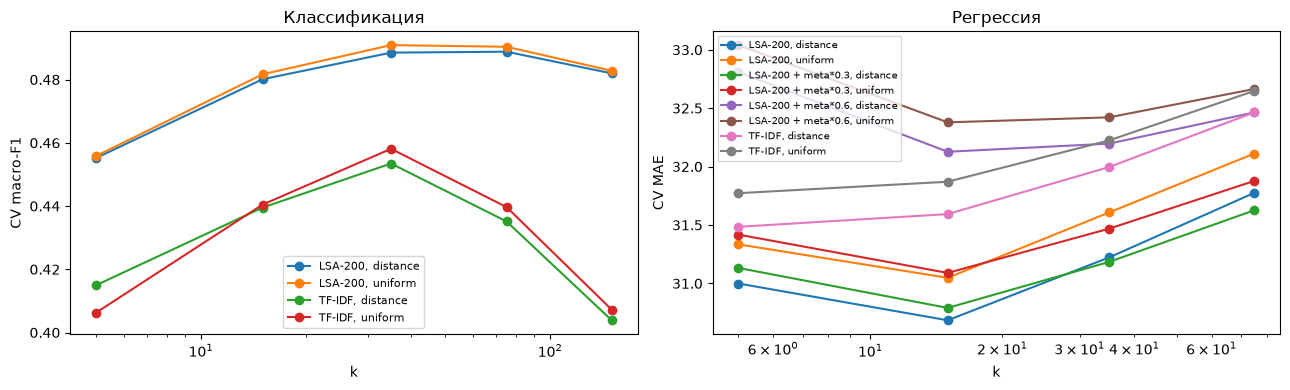

In [12]:
# Кривые CV-качества от k: наглядная проверка H1-H4
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (rep, w), g in cv_c.groupby(["rep", "weights"]):
    ax[0].plot(g["k"], g["cv_f1"], marker="o", label=f"{rep}, {w}")
for (rep, w), g in cv_r.groupby(["rep", "weights"]):
    ax[1].plot(g["k"], g["cv_mae"], marker="o", label=f"{rep}, {w}")
ax[0].set(xscale="log", xlabel="k", ylabel="CV macro-F1", title="Классификация")
ax[1].set(xscale="log", xlabel="k", ylabel="CV MAE", title="Регрессия")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

### 3.3-3.5 Улучшенный бейзлайн
Берём лучшую по CV конфигурацию, обучаем на всём train и оцениваем на тесте.

In [13]:
# Лучшие конфигурации по кросс-валидации
best_c = cv_c.loc[cv_c["cv_f1"].idxmax()]
best_r = cv_r.loc[cv_r["cv_mae"].idxmin()]
print("классификация:", best_c.to_dict()); print("регрессия:", best_r.to_dict())

классификация: {'rep': 'LSA-200', 'k': 35, 'weights': 'uniform', 'cv_f1': 0.4909186246415595}
регрессия: {'rep': 'LSA-200', 'k': 15, 'weights': 'distance', 'cv_mae': 30.6842831316411}


In [14]:
# Признаки улучшенного бейзлайна для теста - в соответствии с выбранным представлением
reps_c_te = {"TF-IDF": (A_tr, A_te), "LSA-200": (La_tr, La_te)}
reps_f_te = {"TF-IDF": (F_tr, F_te), "LSA-200": (Lf_tr, Lf_te),
             "LSA-200 + meta*0.3": (np.hstack([Lf_tr, 0.3 * Mf_tr]), np.hstack([Lf_te, 0.3 * Mf_te])),
             "LSA-200 + meta*0.6": (np.hstack([Lf_tr, 0.6 * Mf_tr]), np.hstack([Lf_te, 0.6 * Mf_te]))}
Xc_tr, Xc_te = reps_c_te[best_c["rep"]]
Xr_tr, Xr_te = reps_f_te[best_r["rep"]]
# Обучение улучшенных моделей на всём train и оценка на тесте
knn_c2 = KNeighborsClassifier(int(best_c["k"]), weights=best_c["weights"]).fit(Xc_tr, ya_tr)
res["classification"]["improved"] = clf_metrics(ya_te, knn_c2.predict(Xc_te))
knn_r2 = KNeighborsRegressor(int(best_r["k"]), weights=best_r["weights"]).fit(Xr_tr, yf_tr)
res["regression"]["improved"] = reg_metrics(yf_te, knn_r2.predict(Xr_te))

In [15]:
# 3.6 Сравнение улучшенного бейзлайна с бейзлайном
results_table(res)

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4226,0.4230,NaN,NaN,NaN
1,classification,improved,0.4888,0.5154,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,30.678,40.915,0.0799
3,regression,improved,NaN,NaN,29.901,39.080,0.1605


У KNN нет встроенной важности признаков, поэтому оцениваем её перестановочно (permutation importance) на части теста: насколько падает качество, если перемешать значения одного признака.

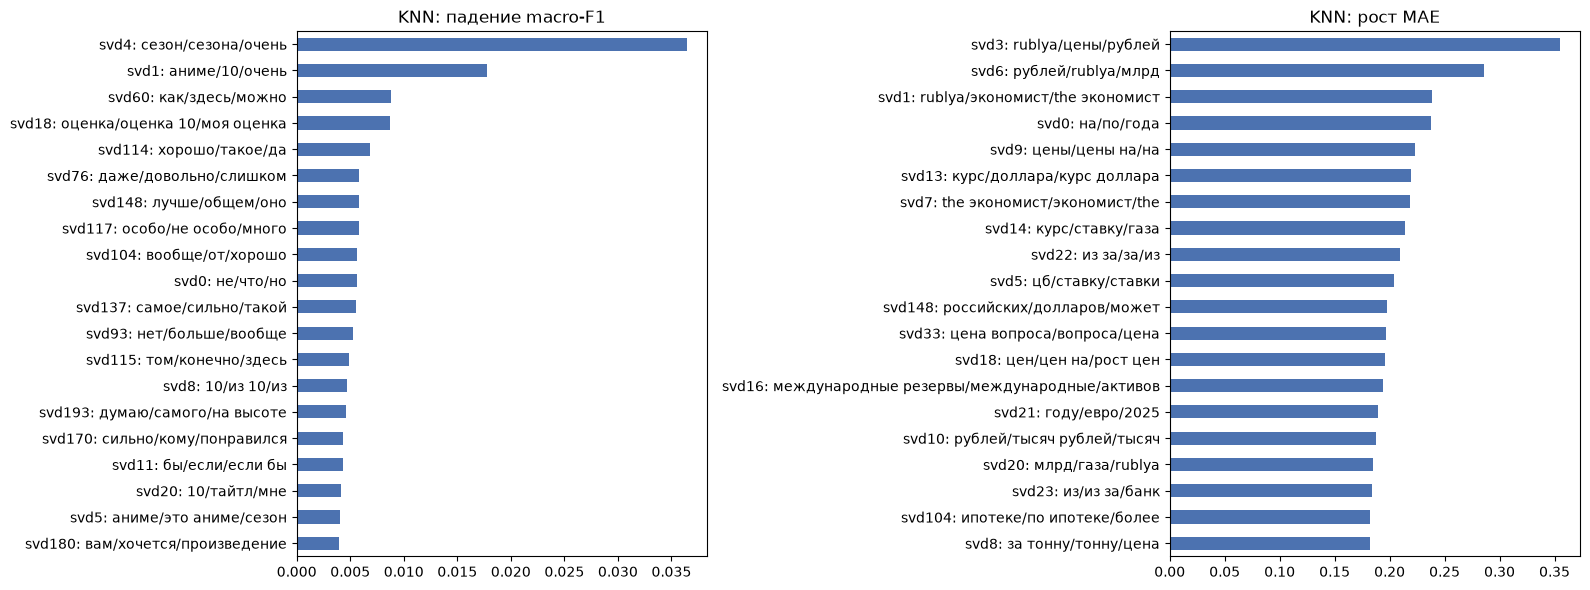

In [16]:
# Permutation importance улучшенного KNN (только для LSA-представления; 3000 объектов теста для скорости)
from sklearn.inspection import permutation_importance
sub = np.random.default_rng(SEED).choice(Xc_te.shape[0], 3000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
if best_c["rep"] == "LSA-200":
    pi = permutation_importance(knn_c2, Xc_te[sub], ya_te[sub], scoring="f1_macro", n_repeats=3, random_state=SEED, n_jobs=-1)
    plot_importance(pi.importances_mean, FEATURE_NAMES["anime"][:200], "KNN: падение macro-F1", ax=ax[0])
if best_r["rep"] != "TF-IDF":
    pi = permutation_importance(knn_r2, Xr_te, yf_te, scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=-1)
    plot_importance(pi.importances_mean, (FEATURE_NAMES["finnews"][:200] + FEATURE_NAMES["meta"])[:Xr_te.shape[1]], "KNN: рост MAE", ax=ax[1])
plt.tight_layout(); plt.show()

### 3.7 Выводы по улучшению

- **H1 (число соседей) подтверждена.** Для классификации качество на CV растёт с k=5 (0.456) до плато при k~35-75 (0.491), дальше падает - слишком широкое соседство размывает границы классов. Для регрессии оптимум меньше - k=15.
- **H2 (взвешивание по расстоянию)** почти ничего не даёт для классификации (разница +-0.002), но стабильно помогает в регрессии (MAE 30.68 против 31.05 при k=15): ближайшие новости точнее задают величину эффекта.
- **H3 (LSA вместо TF-IDF) подтверждена - это главный источник прироста:** при любом k LSA-200 выигрывает у разреженного TF-IDF 0.03-0.08 macro-F1. В пространстве на 20 000 измерений почти все тексты одинаково далеки друг от друга; 200 латентных "тем" дают осмысленную близость.
- **H4 (метаданные) не подтвердилась:** добавление one-hot сферы/источника с весом 0.3 даёт тот же MAE, с весом 0.6 - хуже. Для KNN категориальные признаки искажают метрику расстояния сильнее, чем добавляют сигнала.
- Итог на тесте: macro-F1 **0.423 -> 0.489** (+0.066), accuracy 0.423 -> 0.515; MAE **30.68 -> 29.90**, R2 0.08 -> 0.16.
- Permutation importance показывает, что для отзывов KNN опирается на немногие LSA-компоненты (лексика сезонов/сиквелов, "аниме/10/очень", "моя оценка 10"), а для новостей важность распределена равномерно по многим компонентам: рубль/цены, курс доллара, ставки ЦБ, газ.

## 4. Собственная реализация KNN

Реализация "в лоб" (brute force), но векторизованная: расстояния до всех объектов обучающей выборки считаются
блоками через тождество `||q - x||^2 = ||q||^2 - 2 * q @ x + ||x||^2` (одно матричное умножение на блок),
затем `argpartition` выбирает k ближайших за O(n). Поддерживаются разреженные и плотные матрицы,
евклидова и косинусная метрики, равные веса и веса `1 / d`.

In [17]:
from scipy import sparse


class MyKNN:
    """KNN для классификации (task='clf') и регрессии (task='reg')."""

    def __init__(self, k=5, weights="uniform", metric="euclidean", task="clf", batch=1024):
        self.k, self.weights, self.metric, self.task, self.batch = k, weights, metric, task, batch

    def _prep(self, X):
        # Для косинусной метрики нормируем строки: тогда евклидово расстояние ранжирует так же, как косинусное
        return normalize(X) if self.metric == "cosine" else X

    def fit(self, X, y):
        # "Обучение" KNN - запоминание выборки и предподсчёт квадратов норм
        self.X = self._prep(X)
        self.y = np.asarray(y)
        sq = self.X.multiply(self.X).sum(1) if sparse.issparse(self.X) else (self.X ** 2).sum(1)
        self.sq = np.asarray(sq).ravel()
        if self.task == "clf":
            self.classes_ = np.unique(self.y)
            self.y_idx = np.searchsorted(self.classes_, self.y)
        return self

    def kneighbors(self, Xq):
        # Возвращает (расстояния, индексы) k ближайших соседей, считая блоками по batch объектов
        Xq = self._prep(Xq)
        D, I = [], []
        for s in range(0, Xq.shape[0], self.batch):
            q = Xq[s:s + self.batch]
            qsq = np.asarray(q.multiply(q).sum(1) if sparse.issparse(q) else (q ** 2).sum(1)).ravel()
            prod = q @ self.X.T
            prod = prod.toarray() if sparse.issparse(prod) else prod
            d2 = np.maximum(qsq[:, None] - 2 * prod + self.sq[None, :], 0)
            idx = np.argpartition(d2, self.k - 1, axis=1)[:, :self.k]          # k ближайших без полной сортировки
            dk = np.take_along_axis(d2, idx, 1)
            order = np.argsort(dk, axis=1)                                      # упорядочиваем только k штук
            I.append(np.take_along_axis(idx, order, 1)); D.append(np.sqrt(np.take_along_axis(dk, order, 1)))
        return np.vstack(D), np.vstack(I)

    def _w(self, d):
        # Веса соседей: равные или обратно пропорциональные расстоянию (eps защищает от деления на 0)
        return np.ones_like(d) if self.weights == "uniform" else 1.0 / (d + 1e-9)

    def predict_proba(self, Xq):
        d, i = self.kneighbors(Xq)
        w = self._w(d)
        P = np.zeros((len(i), len(self.classes_)))
        np.add.at(P, (np.arange(len(i))[:, None], self.y_idx[i]), w)          # взвешенное голосование
        return P / P.sum(1, keepdims=True)

    def predict(self, Xq):
        if self.task == "clf":
            return self.classes_[self.predict_proba(Xq).argmax(1)]
        d, i = self.kneighbors(Xq)
        w = self._w(d)
        return (w * self.y[i]).sum(1) / w.sum(1)                               # взвешенное среднее соседей

In [18]:
# Проверка корректности: соседи и предсказания совпадают с sklearn на части теста
m = MyKNN(5).fit(A_tr, ya_tr)
print("совпадение предсказаний с sklearn:", (m.predict(A_te[:500]) == knn_c.predict(A_te[:500])).mean())

совпадение предсказаний с sklearn: 1.0


### 4.2-4.3 Собственная реализация с параметрами бейзлайна
Те же признаки (TF-IDF, 20 000 слов) и те же гиперпараметры (k=5, равные веса, евклидова метрика).

In [19]:
# Обучение и оценка собственного KNN в конфигурации бейзлайна
my_c = MyKNN(5, task="clf").fit(A_tr, ya_tr)
res["classification"]["custom"] = clf_metrics(ya_te, my_c.predict(A_te))
my_r = MyKNN(5, task="reg").fit(F_tr, yf_tr)
res["regression"]["custom"] = reg_metrics(yf_te, my_r.predict(F_te))
# 4.4 Сравнение с бейзлайном sklearn
results_table({t: {s: d[s] for s in ["baseline", "custom"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4226,0.423,NaN,NaN,NaN
1,classification,custom,0.4226,0.423,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,30.678,40.915,0.0799
3,regression,custom,NaN,NaN,30.678,40.915,0.0799


### 4.5 Выводы

Собственная реализация в конфигурации бейзлайна дала **в точности те же метрики**, что и sklearn (macro-F1 0.4226, MAE 30.678), а предсказания совпали на 100% объектов - алгоритм реализован корректно. Векторизация (расстояния через одно матричное умножение на блок + `argpartition`) позволяет обрабатывать 14.6k x 58.6k пар за секунды без деревьев поиска.

### 4.6-4.8 Собственная реализация + техники улучшенного бейзлайна
LSA-представление, косинусная метрика, подобранные на CV k и взвешивание, метаданные для регрессии.

In [20]:
# Собственный KNN с лучшими найденными гиперпараметрами и признаками улучшенного бейзлайна
my_c2 = MyKNN(int(best_c["k"]), weights=best_c["weights"], metric="cosine", task="clf").fit(Xc_tr, ya_tr)
res["classification"]["custom_improved"] = clf_metrics(ya_te, my_c2.predict(Xc_te))
my_r2 = MyKNN(int(best_r["k"]), weights=best_r["weights"], task="reg").fit(Xr_tr, yf_tr)
res["regression"]["custom_improved"] = reg_metrics(yf_te, my_r2.predict(Xr_te))
# 4.9 Сравнение с улучшенным бейзлайном sklearn
results_table({t: {s: d[s] for s in ["improved", "custom_improved"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,improved,0.4888,0.5154,NaN,NaN,NaN
1,classification,custom_improved,0.4888,0.5154,NaN,NaN,NaN
2,regression,improved,NaN,NaN,29.901,39.08,0.1605
3,regression,custom_improved,NaN,NaN,29.901,39.08,0.1605


### 4.10 Выводы

С техниками улучшенного бейзлайна (LSA-200, косинусная метрика, k=35 для классификации; k=15 и веса 1/d для регрессии) собственный KNN снова полностью повторяет sklearn: macro-F1 **0.489**, MAE **29.90**. Прирост относительно собственного бейзлайна такой же, как у sklearn, - улучшение дают представление данных и гиперпараметры, а не реализация.

## Сравнение всех этапов

Сводная таблица метрик на тестовой выборке: бейзлайн (п.2), улучшенный бейзлайн (п.3), собственная реализация (п.4) и собственная реализация с техниками улучшенного бейзлайна.

In [21]:
# Таблица метрик по всем этапам и сохранение в labs/results/LR1.json для итогового ноутбука
table = results_table(res)
save_results("LR1", res)
table

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.4226,0.4230,NaN,NaN,NaN
1,classification,improved,0.4888,0.5154,NaN,NaN,NaN
2,classification,custom,0.4226,0.4230,NaN,NaN,NaN
3,classification,custom_improved,0.4888,0.5154,NaN,NaN,NaN
4,regression,baseline,NaN,NaN,30.678,40.915,0.0799
5,regression,improved,NaN,NaN,29.901,39.080,0.1605
6,regression,custom,NaN,NaN,30.678,40.915,0.0799
7,regression,custom_improved,NaN,NaN,29.901,39.080,0.1605


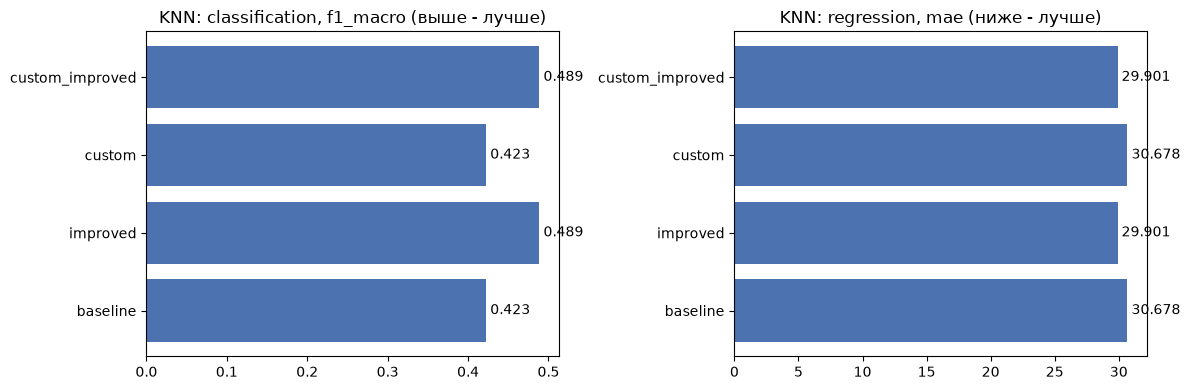

In [22]:
# Визуальное сравнение основной метрики каждой задачи по этапам
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (task, metric) in zip(ax, [("classification", "f1_macro"), ("regression", "mae")]):
    t = table[table["задача"] == task]
    a.barh(t["этап"], t[metric], color="#4C72B0")
    a.set_title(f"KNN: {task}, {metric}" + (" (выше - лучше)" if metric == "f1_macro" else " (ниже - лучше)"))
    for i, v in enumerate(t[metric]):
        a.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## Выводы

1. KNN - самый слабый из "разумных" алгоритмов на текстах: даже лучшая модель даёт macro-F1 0.489 и R2 0.16, что заметно хуже линейных моделей (ЛР2).
2. Решающий фактор качества KNN - пространство признаков: переход от разреженного TF-IDF к LSA дал больше, чем подбор k и весов вместе.
3. Собственная реализация совпадает со sklearn до последнего знака на обоих этапах.
4. Регрессия "влияния новости" оказалась трудной задачей: даже лучшая модель снижает MAE с ~33 (константный прогноз) лишь до ~30 пунктов.